In [5]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np
from datetime import datetime, timedelta


# Define the points of interest
cityName = "Medford, OR"
points = pd.DataFrame({"longitude": [-122.873062], # [Medford, OR]
                       "latitude":  [42.368191],  # [Medford, OR]
                       })
# points = pd.DataFrame({"longitude": [-105.082396, -122.873062], # [Fort Collins, Medford, OR]
#                        "latitude":  [40.548843,    42.368191],  # [Fort Collins, Medford, OR]
#                        })

forecastInit = get_latest_forecast_cycle()
# forecastInit = pd.Timestamp(2025, 3, 5, 18, 0)

# Use the function to calculate forecast range
forecastRange = calculate_forecast_range(forecastInit)



# Generate a table of data

In [6]:
H = FastHerbie(
    [forecastInit],
    model="hrrr",
    product="sfc",
    fxx=forecastRange,
)

# 2m temperature
t2m_HRRR = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest"
                                       )['t2m'].sel(point=0)[1:]

t2m_HRRR = (t2m_HRRR - 273.15) * 1.8 + 32
t2m_max_HRRR = float(t2m_HRRR.max().values)
t2m_min_HRRR = float(t2m_HRRR.min().values)

model_init = convert_time_to_datetime64(t2m_HRRR.time.values)
model_valid_times = convert_time_to_datetime64(t2m_HRRR.valid_time.values)

# 10m wind speed
si10_HRRR = H.xarray(":WIND", backend_kwargs={'decode_times':False}
                     ).herbie.pick_points(points, method="nearest"
                                          )['si10'].sel(point=0)[1:]
si10_max_HRRR = float(si10_HRRR.max().values)
si10_max_HRRR = si10_max_HRRR * 1.94384  # Convert m/s to knots

# Total precipitation
tp_HRRR = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp'].sel(point=0)
tp_HRRR = tp_HRRR * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp_HRRR = tp_HRRR[1:] - tp_HRRR[0]  # Subtract the total precipitation that falls before 06UTC
tp_max_HRRR = float(tp_HRRR.max().values)



In [3]:
# H = FastHerbie([forecastInit], 
#                model="nbm", product="co", 
#                fxx=list(range(6, 30)))
# # H.inventory(":TMP:2 m above ground:.*fcst:nan")
# t2m_NBM = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
#               ).herbie.pick_points(points, method="nearest")['t2m'].sel(point=0)

# t2m_NBM = (t2m_NBM - 273.15) * 1.8 + 32
# t2m_max_NBM = float(t2m_NBM.max().values)
# t2m_min_NBM = float(t2m_NBM.min().values)
# t2m_NBM


In [9]:
# Create the title
title = f"Forecasting for {cityName} - Model initialized {str(model_init)} UTC\nValid: {str(model_valid_times[0])} - {str(model_valid_times[-1])} UTC"
# {tomorrow.strftime('%B %d')} 06UTC - {day_after_tomorrow.strftime('%B %d')} 06UTC"

# Create the table
data = {
    "Model": ["HRRR"],  # "NBM"],
    "High (°F)": [t2m_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Low (°F)": [t2m_min_HRRR],  # np.nan],   # Replace np.nan with actual values if available
    "Precipitation (in)": [tp_max_HRRR],  # np.nan],  # Replace np.nan with actual values if available
    "Wind Speed (kt)": [si10_max_HRRR],  # np.nan]  # Replace np.nan with actual values if available
}

df_forecast = pd.DataFrame(data).round(2)

# Print the title and table without row numbers
print(title)
print(df_forecast.to_string(index=False))

Forecasting for Medford, OR - Model initialized 2025-03-06T18 UTC
Valid: 2025-03-07T06 - 2025-03-08T05 UTC
Model  High (°F)  Low (°F)  Precipitation (in)  Wind Speed (kt)
 HRRR      56.65     33.05                 0.0             4.45


# Generate a time series

In [22]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 30)),
)

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

# t2m_ds


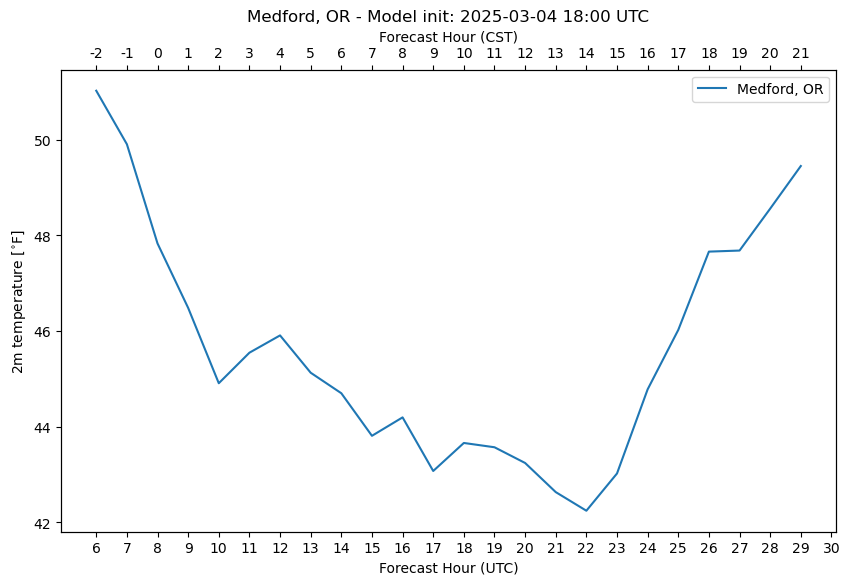

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"{cityName} - Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = t2m_ds.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label=cityName)
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')
ax1.set_xticks(np.arange(6,31))

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-8) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for the city
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

### To DO: Modify the tickmarks such that they update based on when the model was intialized

In [20]:
# Load in the data
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(5, 30)),
)
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp']
tp = tp * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp = tp[1:] - tp[0]  # Subtract the total precipitation that falls before 06UTC
tp


<xarray.DataArray 'tp' (step: 24, point: 1)> Size: 96B
array([[0.00047244],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00082677],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00098425],
       [0.00594489]], dtype=float32)
Coordinates:
    time                 int64 8B 1741132800
  * step                 (step) float64 192B 6.0 7.0 8.0 9.0 ... 27.0 28.0 29.0
    surface              float64 8B 0.0
    latitude             (point) float64 8B 42.36
    longitude            (point) float64 8B 237.1
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 8B 1.457
    point_longitude      (point) float64 8B -122.9
    point_latitude       (point) float64 8B 42.37
Dimensions without coordinates: point

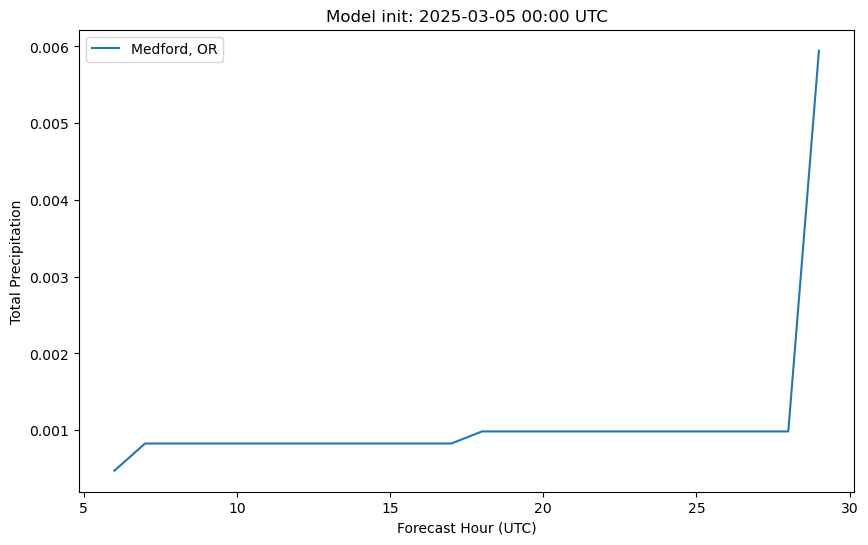

In [22]:

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

city2 = tp.sel(point=0).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), city2, label='Medford, OR')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel('Total Precipitation')

# Add legend
ax1.legend()

plt.show()


# TO DO: convert tp from Kg per square meter to inches. Potentially 0.039370079003585

# Add NBM

In [ ]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 30)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241227]


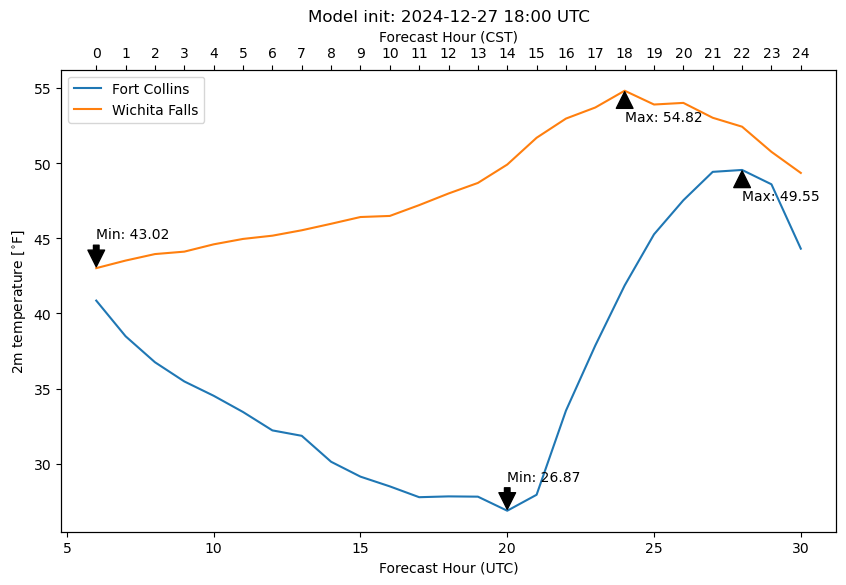

In [ ]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,30), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,30), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,30))
ax2.set_xticklabels([str(h-6) for h in range(6,30)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()